<h1><center>EDA (Exploratory Data Analysis)</h1>
<h2><center> Titanic Dataset

In [228]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


### 1)- Charger les données

In [229]:
# original data copy
data_original = sns.load_dataset('titanic')

In [230]:
data = sns.load_dataset('titanic')

data

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


### 2)- Vérifier la taille des données

In [231]:
data.shape

(891, 15)

We have 891 rows and 15 columns

### 3)- Apperçu sur les données

In [232]:
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 4)- Les types des données

In [233]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


- survived: Whether the passenger survived (1) or not (0).

- pclass: Ticket class (1st, 2nd, or 3rd).

- sex: Gender of the passenger.

- age: Age of the passenger.

- sibsp: Number of siblings/spouses aboard.

- parch: Number of parents/children aboard.

- fare: The fare paid for the ticket.

- embarked: The port where the passenger boarded (C = Cherbourg, Q = Queenstown, S = Southampton).

- class: Categorical representation of pclass.

- who: Categorical representation of passenger type (man, woman, child).

- adult_male: Boolean indicating if the passenger is an adult male.

- deck: Deck level of the cabin.

- embark_town: Full name of the port of embarkation.

- alive: String representation of survival status ("yes" or "no").

- alone: Boolean indicating if the passenger was traveling alone.


### 5)- Statistiques générales

In [234]:
data.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### 6)- Les valeurs manquantes

In [235]:
data.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

#### a)- Traiter les valeurs nulles d'age
<p> On remplace les valuers nulles de la colonne "Age" par la moyenne

In [236]:
# On calcule tout d'abord la moyenne
age_mean = data["age"].mean()
print(f"La moyenne de la colonne age est :  {age_mean}")

# On remplace les valeurs nulles par la moyenne
data["age"].fillna(round(age_mean, 2), inplace=True)
print(data[["age"]])


La moyenne de la colonne age est :  29.69911764705882
      age
0    22.0
1    38.0
2    26.0
3    35.0
4    35.0
..    ...
886  27.0
887  19.0
888  29.7
889  26.0
890  32.0

[891 rows x 1 columns]


In [237]:
data.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

#### b)- Traiter les valeurs nulles de la colonne deck (Deck level of the cabin)
<p> On remplace les valuers nulles de la colonne "deck" par la "Unknown"

In [238]:
data["deck"].unique()

[NaN, 'C', 'E', 'G', 'D', 'A', 'B', 'F']
Categories (7, object): ['A', 'B', 'C', 'D', 'E', 'F', 'G']

In [239]:
print(data["deck"].dtype)

category


In [240]:
data["deck"]= data["deck"].astype('object')

In [241]:
print(data["deck"].dtype)

object


#### Il faut changer le type pour ne pas avoir des erreurs lors du remplacement des valeurs !!

In [242]:
# remplacer 

data["deck"].fillna('Unknown', inplace=True)
data["deck"].unique()


array(['Unknown', 'C', 'E', 'G', 'D', 'A', 'B', 'F'], dtype=object)

In [243]:
data.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
class          0
who            0
adult_male     0
deck           0
embark_town    2
alive          0
alone          0
dtype: int64

#### c)- Traiter les valeurs nulles de la colonne embarked et al colonne embark_town
<p> On va supprimer les valuers nulles de ces deux colonnes


In [244]:
data.dropna(inplace=True)
print(data.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alive          0
alone          0
dtype: int64


### 7)- Les valeurs dupliquées

In [245]:
data.duplicated().sum()

107

#### Traiter les valeurs dupliquées
<p> On va supprimer les valeurs dupliquées

In [246]:
data.drop_duplicates(inplace=True)
print(data.duplicated().sum())

0


### 8)- Standariser les formats

### 8-1) - Vérifier les valeurs uniques ainsi que les colonnes pareils

#### a)- colonne survived

In [247]:
data['survived'].unique() # pas de standarisation

array([0, 1], dtype=int64)

#### b)- colonne pclass         


In [248]:
data['pclass'].unique()  # pas de standarisation

array([3, 1, 2], dtype=int64)

#### c)- colonne sex            
         

In [249]:
data['sex'].unique() # pas de standarisation

array(['male', 'female'], dtype=object)

#### d)- colonne age            


In [250]:
print(data['age'].unique())
print("\n\n max age: ", max(data['age']))
print("\n\n min age: ", min(data['age']))

[22.   38.   26.   35.   29.7  54.    2.   27.   14.    4.   58.   20.
 39.   55.   31.   34.   15.   28.    8.   19.   40.   66.   42.   21.
 18.    3.    7.   49.   29.   65.   28.5   5.   11.   45.   17.   32.
 16.   25.    0.83 30.   33.   23.   24.   46.   59.   71.   37.   47.
 14.5  70.5  32.5  12.    9.   36.5  51.   55.5  40.5  44.    1.   61.
 56.   50.   36.   45.5  20.5  62.   41.   52.   63.   23.5   0.92 43.
 60.   10.   64.   13.   48.    0.75 53.   57.   80.   70.   24.5   6.
  0.67 30.5   0.42 34.5  74.  ]


 max age:  80.0


 min age:  0.42


In [251]:
print(data[data['age']<1]['age']) # il y a des valeurs < 1 ans (des bébés)


78     0.83
305    0.92
469    0.75
755    0.67
803    0.42
831    0.83
Name: age, dtype: float64


In [252]:

# on va remplacer ces valeurs par 1 (on peut garder ces valeurs comme elles sont !!!)
data.loc[data['age']< 1, 'age' ] = 1

#### e)- colonne sibsp          


In [253]:
data['sibsp'].unique()

array([1, 0, 3, 4, 2, 5, 8], dtype=int64)

#### f)- colonne parch          


In [254]:
data['parch'].unique()

array([0, 1, 2, 5, 3, 4, 6], dtype=int64)

#### g)- colonne fare           


In [255]:
data['fare'].max(), data['fare'].min()

(512.3292, 0.0)

#### h)- colonne embarked et colonne embark_town    

In [256]:
data['embarked'].unique(), data['embark_town'].unique()

(array(['S', 'C', 'Q'], dtype=object),
 array(['Southampton', 'Cherbourg', 'Queenstown'], dtype=object))

ici on a deux colonnes qui sont les memes on va supprimer la colonne 'embarked'

In [257]:
data.drop(columns=['embarked'], inplace=True)

data.head(2)

,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,Third,man,True,Unknown,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,First,woman,False,C,Cherbourg,yes,False


#### i)- colonne class          


In [258]:
data['class'].unique() # cette colonne est comme pclass donc on la supprime

['Third', 'First', 'Second']
Categories (3, object): ['First', 'Second', 'Third']

In [259]:
data.drop(columns=['pclass'], inplace=True)
data.head(2)

,survived,sex,age,sibsp,parch,fare,class,who,adult_male,deck,embark_town,alive,alone
0,0,male,22.0,1,0,7.2500,Third,man,True,Unknown,Southampton,no,False
1,1,female,38.0,1,0,71.2833,First,woman,False,C,Cherbourg,yes,False


#### j)- colonne who            


In [260]:
data['who'].unique()

array(['man', 'woman', 'child'], dtype=object)

#### k)- colonne adult_male     


In [261]:
data['adult_male'].unique()

array([ True, False])

#### l)- colonne deck           


In [262]:
data['deck'].unique()

array(['Unknown', 'C', 'E', 'G', 'D', 'A', 'B', 'F'], dtype=object)

#### m)- colonne alive          


In [263]:
data['alive'].unique() # c'est comme la colonne survived donc à supprimer


array(['no', 'yes'], dtype=object)

In [264]:
data.drop(columns=['alive'], inplace=True)
data.head(2)

,survived,sex,age,sibsp,parch,fare,class,who,adult_male,deck,embark_town,alone
0,0,male,22.0,1,0,7.2500,Third,man,True,Unknown,Southampton,False
1,1,female,38.0,1,0,71.2833,First,woman,False,C,Cherbourg,False


#### n)- colonne alone

In [265]:
data['alone'].unique()

array([False,  True])

In [266]:
clean_data = data  # dataset finale nettoyée (garder une copie)
clean_data.head()

,survived,sex,age,sibsp,parch,fare,class,who,adult_male,deck,embark_town,alone
0,0,male,22.0,1,0,7.2500,Third,man,True,Unknown,Southampton,False
1,1,female,38.0,1,0,71.2833,First,woman,False,C,Cherbourg,False
2,1,female,26.0,0,0,7.9250,Third,woman,False,Unknown,Southampton,True
3,1,female,35.0,1,0,53.1000,First,woman,False,C,Southampton,False
4,0,male,35.0,0,0,8.0500,Third,man,True,Unknown,Southampton,True


### 8-2) - Supprimer les colonnes inutiles

- survived: Whether the passenger survived (1) or not (0).

- sex: Gender of the passenger.

- age: Age of the passenger.

- sibsp: Number of siblings/spouses aboard.

- parch: Number of parents/children aboard.

- fare: The fare paid for the ticket.

- class: Categorical representation of pclass.

- who: Categorical representation of passenger type (man, woman, child).

- adult_male: Boolean indicating if the passenger is an adult male.

- deck: Deck level of the cabin.

- embark_town: Full name of the port of embarkation.

- alone: Boolean indicating if the passenger was traveling alone.


In [267]:
data.drop(columns=['sibsp', 'parch', 'adult_male', 'embark_town', 'deck', 'who'], inplace=True)

data.head()

,survived,sex,age,fare,class,alone
0,0,male,22.0,7.2500,Third,False
1,1,female,38.0,71.2833,First,False
2,1,female,26.0,7.9250,Third,True
3,1,female,35.0,53.1000,First,False
4,0,male,35.0,8.0500,Third,True


In [268]:
new_clean_data = data # data sans les colonnes inutiles !!

### 9)- Visualisation des données

In [146]:
data['survived'].value_counts()

0    461
1    321
Name: survived, dtype: int64

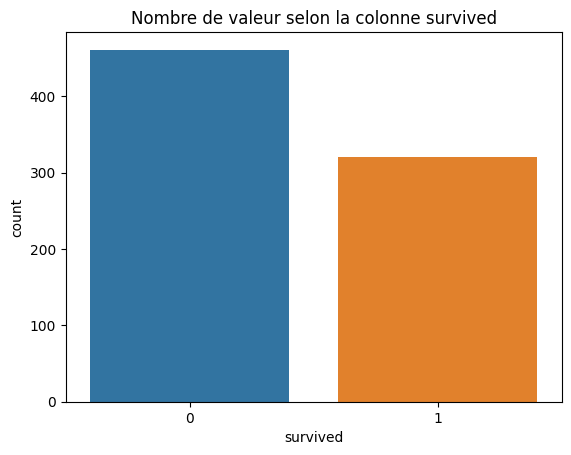

In [147]:
sns.countplot(data= data, x='survived')
plt.title("Nombre de valeur selon la colonne survived")
plt.show()

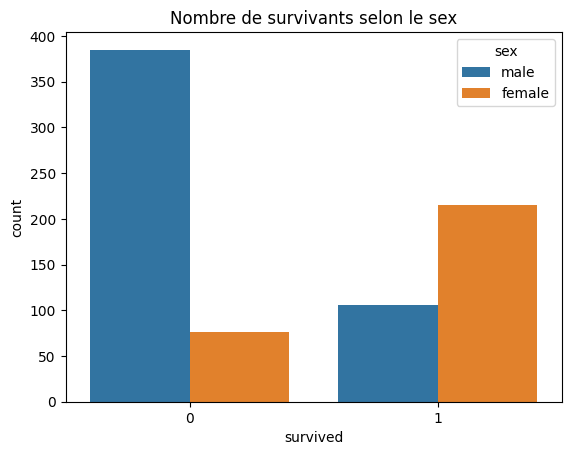

In [270]:
sns.countplot(data= data, x='survived', hue='sex')
plt.title("Nombre de survivants selon le sex")
plt.show()

In [273]:
data.head(2)

,survived,sex,age,fare,class,alone
0,0,male,22.0,7.2500,Third,False
1,1,female,38.0,71.2833,First,False


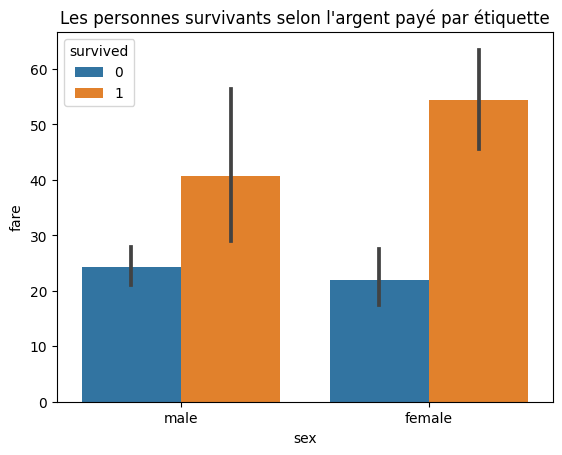

In [279]:
sns.barplot(data= data, y='fare', x='sex', hue='survived')
plt.title("Les personnes survivants selon l'argent payé par étiquette")
plt.show()

c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_stats\counting.py:140: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  bin_edges = np.histogram_bin_edges(vals, bins, binrange, weight)
c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_stats\counting.py:179: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  hist, edges = np.histogram(vals, **bin_kws, weights=weights, density=density)


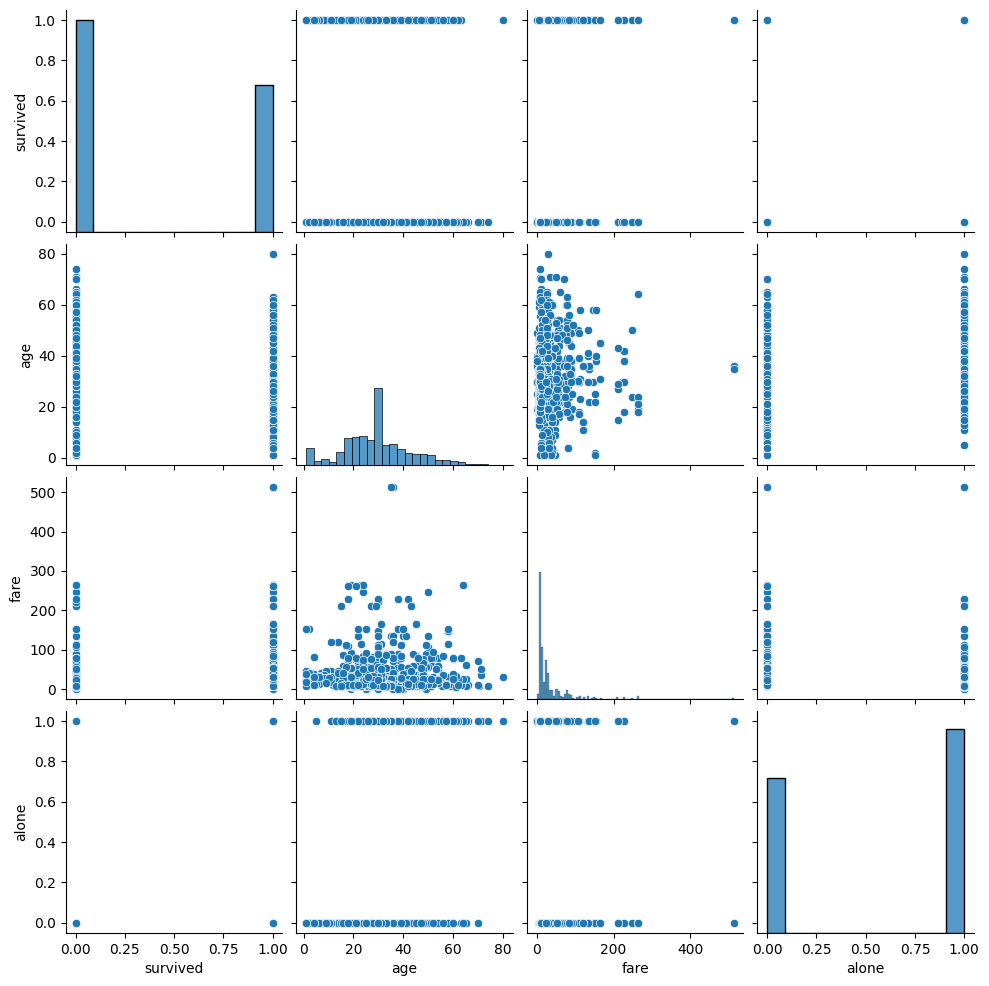

In [291]:

sns.pairplot(data=data)
plt.show()

### Matrice de corrélation

In [294]:
corr_mat = data.corr(numeric_only=True)
print(corr_mat)

          survived       age      fare     alone
survived  1.000000 -0.085343  0.244798 -0.179758
age      -0.085343  1.000000  0.086606  0.193394
fare      0.244798  0.086606  1.000000 -0.249035
alone    -0.179758  0.193394 -0.249035  1.000000


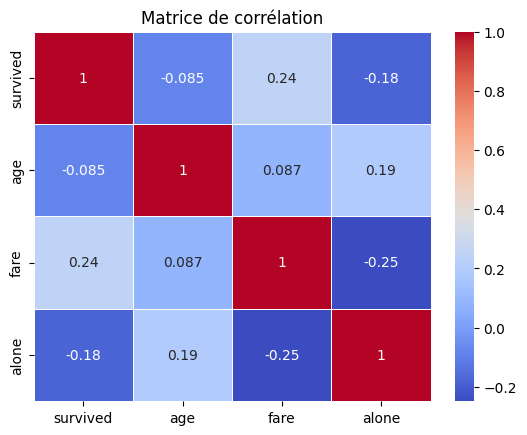

In [297]:
sns.heatmap(corr_mat, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Matrice de corrélation")
plt.show()

In [299]:
data.head(1)

,survived,sex,age,fare,class,alone
0,0,male,22.0,7.25,Third,False


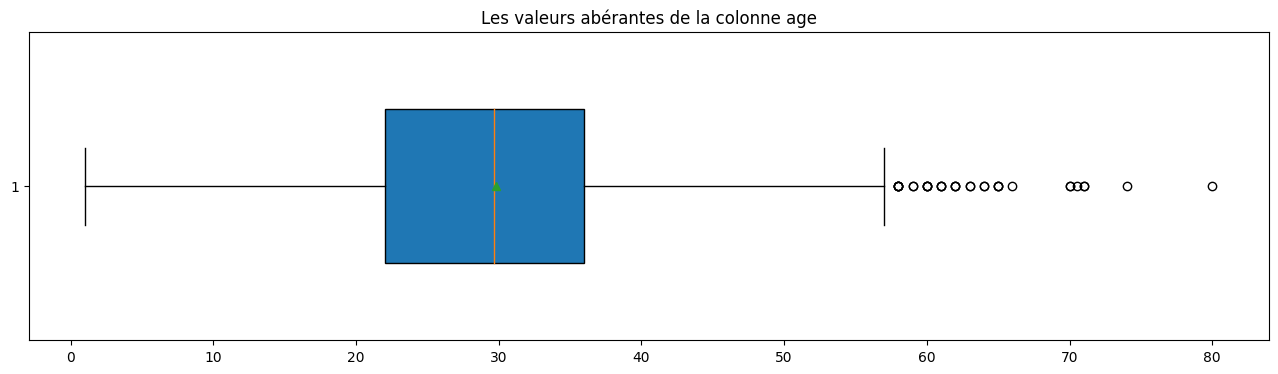

In [318]:
plt.figure(figsize=(16,4))
plt.boxplot(data['age'], showmeans=True, patch_artist=True, vert=False, widths=0.5)
plt.title("Les valeurs abérantes de la colonne age")
plt.show()

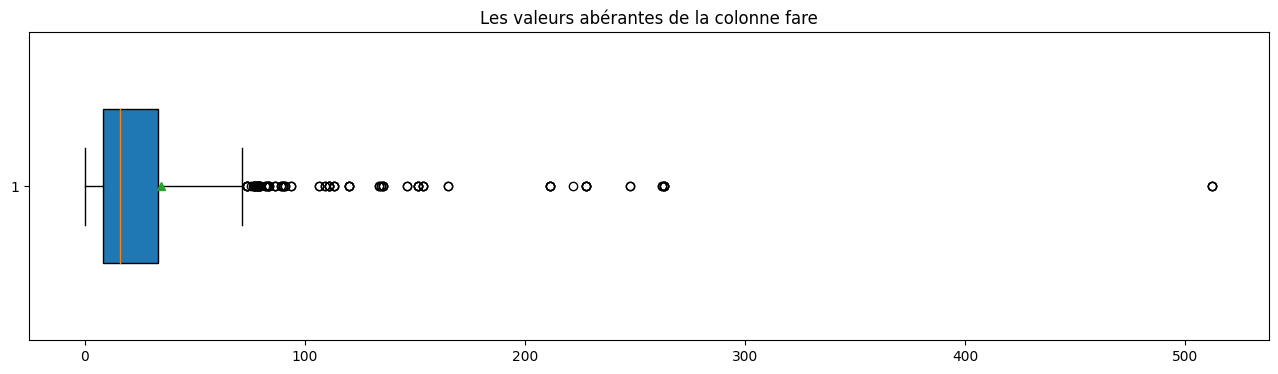

In [319]:
plt.figure(figsize=(16,4))
plt.boxplot(data['fare'], showmeans=True, patch_artist=True, vert=False, widths=0.5)
plt.title("Les valeurs abérantes de la colonne fare")
plt.show()

In [320]:
# On va garder ces valeurs puisqu'elles sont correctes

<h1><center> THE END :)

No AI has been used in this work !!!